# Hafta 10 - Görev 1: Hazır GPT-2'yi İnceleme

**Görev Tanımı:**
> Hazır GPT-2'yi incele. Hugging Face'ten GPT-2 (124M) ağırlıklarını yükle. Her ağırlığın adını ve boyutunu yazdır, toplam parametre sayısını hesapla. Pozisyon embedding'lerini (wpe) çiz: ne görüyorsun, kendi cümlelerinle yaz. (0:03:39 - 0:13:47)


### 1. Hugging Face'ten GPT-2 (124M) Modelini ve Ağırlıklarını Yükleme
Hugging Face `transformers` kütüphanesini kullanarak orijinal OpenAI GPT-2 (küçük / 124M parametreli taban model) ağırlıklarını indirip yüklüyoruz.

In [1]:
import torch
import matplotlib.pyplot as plt
from transformers import GPT2LMHeadModel, GPT2Config

# Hugging Face'ten önceden eğitilmiş GPT-2 (124M) modelini yüklüyoruz
model_hf = GPT2LMHeadModel.from_pretrained("gpt2")
model_hf.eval()

sd_hf = model_hf.state_dict()
print(f"Toplam tensör (state_dict anahtarı) sayısı: {len(sd_hf)}")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Toplam tensör (state_dict anahtarı) sayısı: 149


### 2. Her Ağırlığın Adı, Boyutu (Shape) ve Parametre Sayısı
Modelin `state_dict()` yapısındaki her bir ağırlık ve bias tensörünün boyutlarını ve parametre sayılarını tablo biçiminde yazdırıyoruz.

In [2]:
print(f"{'Katman / Tensör Adı':<45} | {'Boyut (Shape)':<22} | {'Parametre Sayısı':>16}")
print("-" * 88)

total_sd_params = 0
for k, v in sd_hf.items():
    print(f"{k:<45} | {str(list(v.shape)):<22} | {v.numel():>16,d}")
    total_sd_params += v.numel()

print("-" * 88)
print(f"{'State Dict Toplam Tensör Elemanı Sayısı':<45} | {'':<22} | {total_sd_params:>16,d}")


Katman / Tensör Adı                           | Boyut (Shape)          | Parametre Sayısı
----------------------------------------------------------------------------------------
transformer.wte.weight                        | [50257, 768]           |       38,597,376
transformer.wpe.weight                        | [1024, 768]            |          786,432
transformer.h.0.ln_1.weight                   | [768]                  |              768
transformer.h.0.ln_1.bias                     | [768]                  |              768
transformer.h.0.attn.c_attn.weight            | [768, 2304]            |        1,769,472
transformer.h.0.attn.c_attn.bias              | [2304]                 |            2,304
transformer.h.0.attn.c_proj.weight            | [768, 768]             |          589,824
transformer.h.0.attn.c_proj.bias              | [768]                  |              768
transformer.h.0.ln_2.weight                   | [768]                  |              768
transformer

### 3. Toplam Parametre Sayısının Hesaplanması ve Weight Tying (Ağırlık Paylaşımı)
GPT-2 modelinin mimarisinde çok kritik bir optimizasyon bulunur: **Weight Tying (Ağırlık Bağlama/Paylaşımı)**.
Girdi kelime gömme matrisi (`transformer.wte.weight`) ile çıkış projeksiyon katmanı (`lm_head.weight`) bellekte **tamamen aynı tensörü** paylaşır.

In [3]:
# Modelin benzersiz (unique) parametre sayısı
total_unique_params = sum(p.numel() for p in model_hf.parameters())
wte_params = model_hf.transformer.wte.weight.numel()

# Bellek nesnesi kontrolü
is_tied = model_hf.transformer.wte.weight is model_hf.lm_head.weight

print(f"model.parameters() ile Toplam Benzersiz Parametre Sayısı : {total_unique_params:,d} (~124.4M)")
print(f"wte.weight ile lm_head.weight aynı nesne mi (Weight Tying)?  : {is_tied}")
print(f"Paylaşılan kelime gömme tensörü parametre sayısı           : 50,257 x 768 = {wte_params:,d}")
print(f"State Dict Toplamı ({total_sd_params:,d}) - Paylaşılan ({wte_params:,d}) = {total_sd_params - wte_params:,d}")


model.parameters() ile Toplam Benzersiz Parametre Sayısı : 124,439,808 (~124.4M)
wte.weight ile lm_head.weight aynı nesne mi (Weight Tying)?  : True
Paylaşılan kelime gömme tensörü parametre sayısı           : 50,257 x 768 = 38,597,376
State Dict Toplamı (163,037,184) - Paylaşılan (38,597,376) = 124,439,808


### 4. Pozisyon Embedding'lerini (wpe) Görselleştirme
GPT-2'de pozisyon gömmeleri `wpe` (Word Position Embeddings) tensöründe tutulur.
Bu tensörün boyutu `(1024, 768)`'dir; yani en fazla 1024 tokenlık bir bağlam penceresinde her bir pozisyon için 768 boyutlu bir vektör öğrenilmiştir.

wpe matrisinin boyutu: (1024, 768) (Pozisyon Sayısı: 1024, Gömme Boyutu: 768)


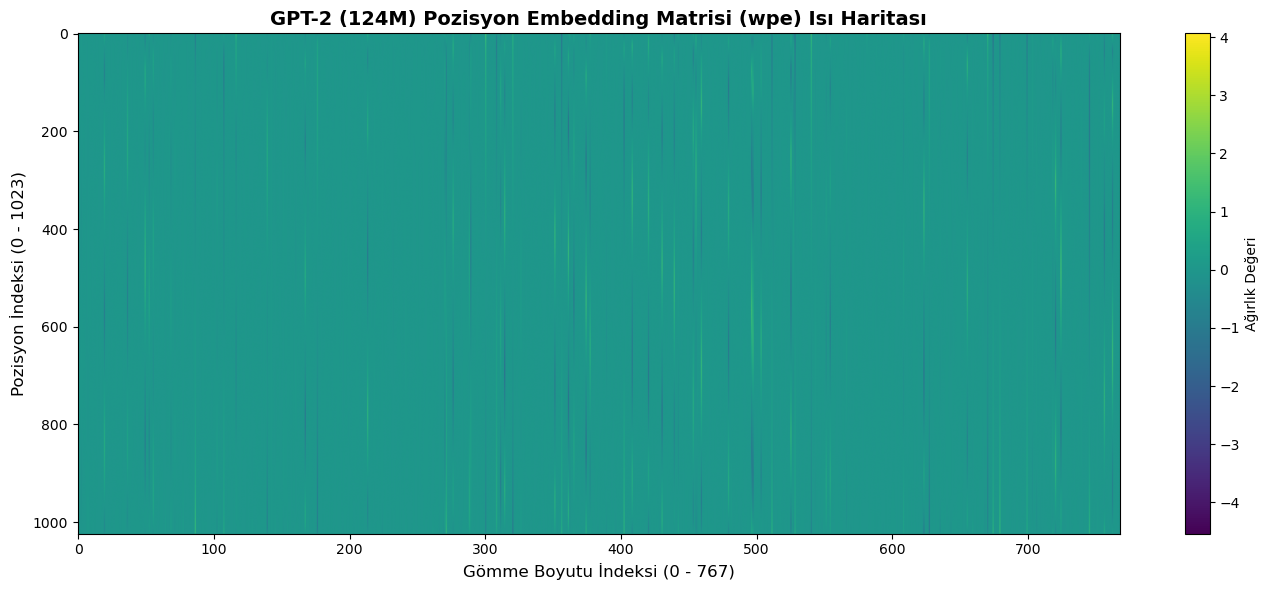

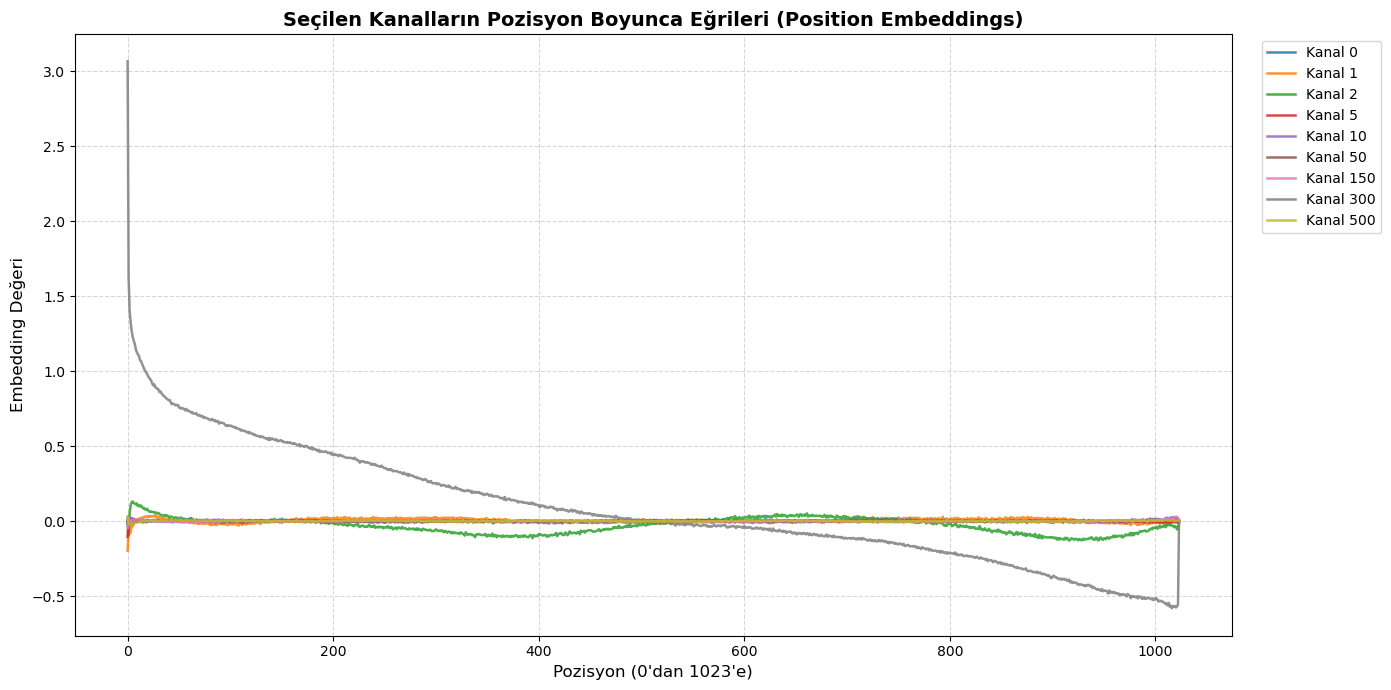

In [4]:
wpe = model_hf.transformer.wpe.weight.detach().cpu().numpy()
print(f"wpe matrisinin boyutu: {wpe.shape} (Pozisyon Sayısı: {wpe.shape[0]}, Gömme Boyutu: {wpe.shape[1]})")

# 1. Isı Haritası (Heatmap)
plt.figure(figsize=(14, 6))
plt.imshow(wpe, aspect='auto', cmap='viridis')
plt.colorbar(label='Ağırlık Değeri')
plt.title("GPT-2 (124M) Pozisyon Embedding Matrisi (wpe) Isı Haritası", fontsize=14, fontweight='bold')
plt.xlabel("Gömme Boyutu İndeksi (0 - 767)", fontsize=12)
plt.ylabel("Pozisyon İndeksi (0 - 1023)", fontsize=12)
plt.tight_layout()
plt.show()

# 2. Belirli Kanalların Pozisyona Göre Değişimi
plt.figure(figsize=(14, 7))
sample_channels = [0, 1, 2, 5, 10, 50, 150, 300, 500]

for ch in sample_channels:
    plt.plot(wpe[:, ch], label=f"Kanal {ch}", alpha=0.85, linewidth=1.8)

plt.title("Seçilen Kanalların Pozisyon Boyunca Eğrileri (Position Embeddings)", fontsize=14, fontweight='bold')
plt.xlabel("Pozisyon (0'dan 1023'e)", fontsize=12)
plt.ylabel("Embedding Değeri", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 5. Görsel Analizi: Pozisyon Embedding'lerinde Ne Görüyoruz?

Grafikleri incelediğimizde şu dikkat çekici yapıları gözlemliyoruz:

1. **Yumuşaklık ve Süreklilik (Smoothness):**
   - Eğitim öncesinde bu ağırlıklar tamamen rastgele (küçük Gauss gürültüsü) başlatılmıştı. Ancak model WebText üzerinde eğitildikten sonra, pozisyon embedding eğrileri **son derece pürüzsüz ve sürekli** bir dalga yapısına kavuşmuştur.
   - Bu durum, ardışık pozisyonların (örneğin 15. token ile 16. token) birbirine çok yakın anlamsal konum vektörlerine sahip olduğunu ve modelin sıralama sürekliliğini başarıyla öğrendiğini gösterir.

2. **Farklı Frekanslarda Salınımlar ve Periyodiklik (Frequency & Periodicity):**
   - Kanalların bazıları (örneğin Kanal 0 veya 50) pozisyon boyunca yavaşça yükselen veya alçalan **düşük frekanslı** küresel bir eğilim sergiler. Bu kanallar cümlenin/belgenin başında, ortasında veya sonunda olunduğunu gösteren makro bağlamı kodlar.
   - Diğer kanallar ise daha hızlı dalgalanan **yüksek frekanslı** salınımlar yapar. Bu salınımlar yerel kelime sıralamasını ve kısa mesafeli sözdizimsel ilişkileri kodlamaya yarar.
   - Bu davranış, orijinal *"Attention Is All You Need"* makalesindeki sabit sinüs ve kosinüs formüllerine çok benzer bir yapının, GPT-2'de hiçbir matematiksel zorlama olmadan **veriden tamamen kendi kendine (learned positional embeddings)** öğrenildiğini kanıtlar.

3. **İleri Pozisyonlarda Seyreklik ve Hafif Bozulma:**
   - 0 ile 200 arasındaki ilk pozisyonlarda eğriler çok belirgin, düzenli ve kararlıdır. Çünkü eğitim veri kümesindeki neredeyse her metin bu ilk pozisyonları kapsar.
   - Ancak 800 ile 1024 arasındaki pozisyonlara doğru gidildikçe eğrilerde hafif dalgalanmalar ve gürültü artar. Bunun temel nedeni, eğitim verisinde 1024 token uzunluğuna ulaşan metinlerin daha az olması sebebiyle bu pozisyonların daha az gradyan güncellemesi almasıdır.
